# Training a linear model (logistic regression)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    KFold,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.exceptions import UndefinedMetricWarning
from datatypes import CLEAN_SQF
import warnings

# Silence warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)
warnings.filterwarnings("ignore", category=UserWarning)

## Main analysis
### Split dataset into training and testing sets

In [2]:
clean_df = pd.read_csv(CLEAN_SQF)

features = clean_df.columns.difference(["USE_OF_FORCE_FLAG"]).values
X = clean_df[features]
y = clean_df["USE_OF_FORCE_FLAG"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

### Create a logistic regression model and tune hyperparameters

In [11]:
# Initialize logistic regression model, using saga as solver to test elastic net regularization
logreg = LogisticRegression(
    solver="liblinear", class_weight="balanced", random_state=123
)

# Define how data should be split, using a specified seed
cv_split = KFold(n_splits=5, shuffle=True, random_state=123)

# Define parameter grid for hyperparameter tuning
param_grid = {
    "penalty": ["l1", "l2"],
    "C": [1.0, 0.1, 0.01, 0.001, 0.0001],
}

### Note to team: Initially wanted to include elasticnet in the tuning process (we will have to change to solver="saga"),
###               but the best hyperparameters from the process resulted in coefficients that will not allow any y to be >= 0.5, so I changed back to the above
###               Alternatively, we can use the below for robustness but state it as a limitation of the model?

# param_grid = [
#     {
#         "penalty": ["l1", "l2"],
#         "C": [1.0, 0.1, 0.01, 0.001, 0.0001],
#     },
#     {
#         "penalty": ["elasticnet"],
#         "C": [1.0, 0.1, 0.01, 0.001, 0.0001],
#         "l1_ratio": np.linspace(0, 1, 6)[1:-1],
#     },
# ]

scoring = ["accuracy", "precision", "recall", "f1"]

# Initialize GridSearchCV, using the default 5-fold cross-validation, with tuning based on recall (our primary metric)
grid_search = GridSearchCV(
    logreg,
    param_grid=param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_split,
    verbose=1,
)

# Run GridSearchCV
grid_search.fit(X_train, y_train)

print(
    "Using recall, the best hyperparameters resulting in the highest score are as follows."
)
print(f"Best hyperparameters: {grid_search.best_params_}")
print(f"Best score (recall): {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Using recall, the best hyperparameters resulting in the highest score are as follows.
Best hyperparameters: {'C': 0.01, 'penalty': 'l1'}
Best score (recall): 0.6571


### Display results (mean score and rank for each metric) for each C-penalty hyperparameter combination

In [4]:
results = pd.DataFrame(grid_search.cv_results_)[
    [
        "param_C",
        "param_penalty",
        "params",
        "mean_test_accuracy",
        "rank_test_accuracy",
        "mean_test_precision",
        "rank_test_precision",
        "mean_test_recall",
        "rank_test_recall",
        "mean_test_f1",
        "rank_test_f1",
    ]
]
results

,param_C,param_penalty,params,mean_test_accuracy,rank_test_accuracy,mean_test_precision,rank_test_precision,mean_test_recall,rank_test_recall,mean_test_f1,rank_test_f1
0,1.0000,l1,"{'C': 1.0, 'penalty': 'l1'}",0.606701,4,0.304234,2,0.630608,6,0.410352,4
1,1.0000,l2,"{'C': 1.0, 'penalty': 'l2'}",0.608468,3,0.305350,1,0.630131,7,0.411264,3
2,0.1000,l1,"{'C': 0.1, 'penalty': 'l1'}",0.598778,7,0.301824,4,0.645921,2,0.411328,1
3,0.1000,l2,"{'C': 0.1, 'penalty': 'l2'}",0.605317,5,0.304194,3,0.635383,5,0.411310,2
4,0.0100,l1,"{'C': 0.01, 'penalty': 'l1'}",0.583982,10,0.294644,7,0.657063,1,0.406785,6
5,0.0100,l2,"{'C': 0.01, 'penalty': 'l2'}",0.597203,8,0.300346,5,0.643265,3,0.409390,5
6,0.0010,l1,"{'C': 0.001, 'penalty': 'l1'}",0.782874,1,0.000000,9,0.000000,9,0.000000,9
7,0.0010,l2,"{'C': 0.001, 'penalty': 'l2'}",0.591285,9,0.296547,6,0.643089,4,0.405850,7
8,0.0001,l1,"{'C': 0.0001, 'penalty': 'l1'}",0.782874,1,0.000000,9,0.000000,9,0.000000,9
9,0.0001,l2,"{'C': 0.0001, 'penalty': 'l2'}",0.601785,6,0.294393,8,0.596945,8,0.394242,8


### Obtain model weights and bias using tuned hyperparameters (based on recall)

In [5]:
# Obtain the best model using the tuned GridSearchCV hyperparameters
best_model = grid_search.best_estimator_

# Extract the weights and bias term from the best model
weights = best_model.coef_[0]
feature_weights = pd.Series(weights, index=X_train.columns)
bias_term = best_model.intercept_[0]

print("Using the tuned hyperparameters, the estimated coefficients are:")
print()
print(feature_weights.sort_values(ascending=False))
print()
print(f"The estimated bias term is {bias_term}")

Using the tuned hyperparameters, the estimated coefficients are:

STOP_LOCATION_PATROL_BORO_NAME_PBMS                                        0.495794
SUSPECT_SEX_male                                                           0.154975
STOP_LOCATION_PATROL_BORO_NAME_PBMN                                        0.065122
SUSPECT_REPORTED_AGE_25–44                                                 0.060493
SUSPECT_RACE_DESCRIPTION_black                                             0.036850
STOP_LOCATION_PATROL_BORO_NAME_PBQN                                        0.000000
SUSPECTED_CRIME_DESCRIPTION_criminal mischief                              0.000000
SUSPECTED_CRIME_DESCRIPTION_cpsp                                           0.000000
SUSPECTED_CRIME_DESCRIPTION_auto stripping                                 0.000000
SUSPECTED_CRIME_DESCRIPTION_burglary                                       0.000000
SUSPECTED_CRIME_DESCRIPTION_criminal possession of controlled substance    0.000000
STOP_LOCAT

### Predict labels on test set and obtain key evaluation metrics from predictions using tuned hyperparameters (based on recall)

              precision    recall  f1-score   support

           0       0.86      0.56      0.68      4107
           1       0.30      0.68      0.41      1131

    accuracy                           0.59      5238
   macro avg       0.58      0.62      0.55      5238
weighted avg       0.74      0.59      0.62      5238



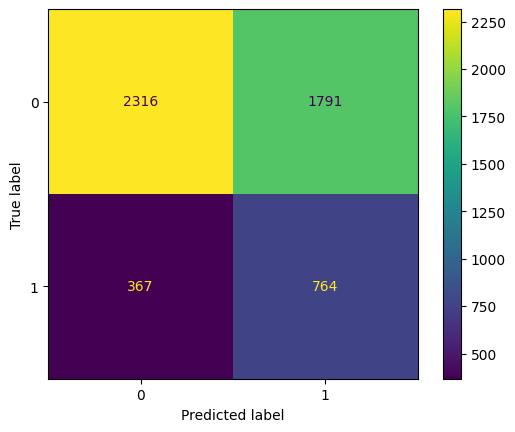

In [6]:
y_pred = grid_search.predict(X_test)
print(classification_report(y_test, y_pred))

# Create a confusion matrix
y_labels = np.unique(y_test)
cm = confusion_matrix(y_test, y_pred, labels=y_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=y_labels)
disp.plot()
plt.show()

## Supplementary analysis
### Predict labels on test set using tuned hyperparameters (based on other metrics for comparison) and obtain key metrics from predictions

Using accuracy: the best C is 0.001 and the best penalty is l1, resulting in a score of 0.7829.
Evaluating the model with these hyperparameters gives us the following metrics.
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      4107
           1       0.00      0.00      0.00      1131

    accuracy                           0.78      5238
   macro avg       0.39      0.50      0.44      5238
weighted avg       0.61      0.78      0.69      5238



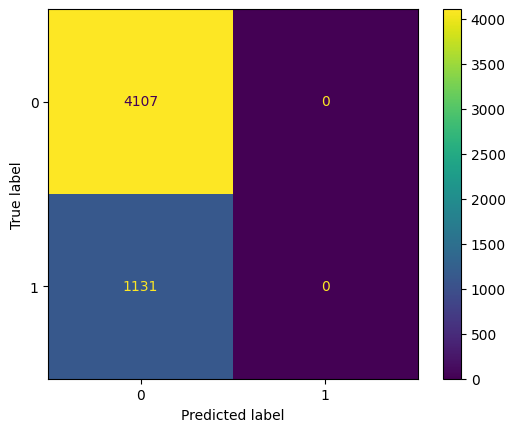


Using precision: the best C is 1.0 and the best penalty is l2, resulting in a score of 0.3053.
Evaluating the model with these hyperparameters gives us the following metrics.
              precision    recall  f1-score   support

           0       0.85      0.60      0.70      4107
           1       0.30      0.63      0.41      1131

    accuracy                           0.60      5238
   macro avg       0.58      0.61      0.56      5238
weighted avg       0.74      0.60      0.64      5238



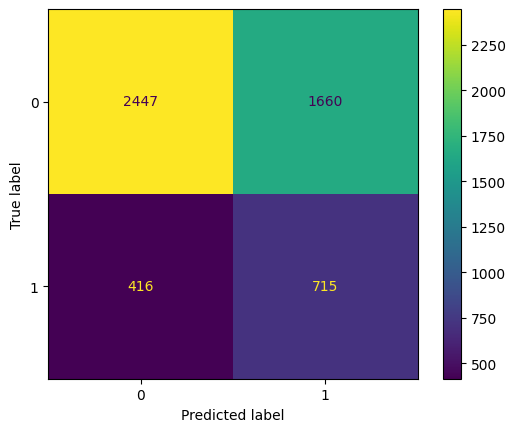


Using f1: the best C is 0.1 and the best penalty is l1, resulting in a score of 0.4113.
Evaluating the model with these hyperparameters gives us the following metrics.
              precision    recall  f1-score   support

           0       0.86      0.58      0.69      4107
           1       0.30      0.64      0.41      1131

    accuracy                           0.60      5238
   macro avg       0.58      0.61      0.55      5238
weighted avg       0.74      0.60      0.63      5238



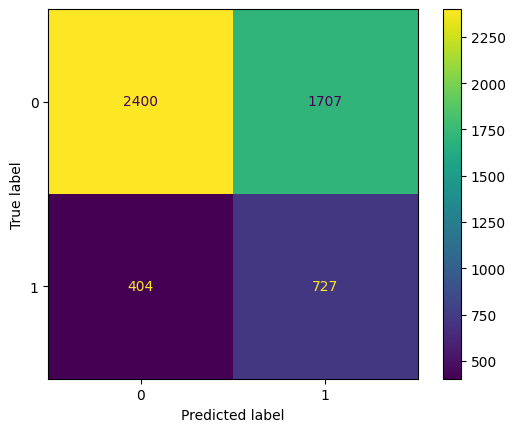

In [ ]:
scoring_ex_recall = [metric for metric in scoring if metric != "recall"]
results_df = pd.DataFrame(results)

# Loop through scoring metrics
for metric in scoring_ex_recall:
    # Get index of the row with the best score and rank for the given metric
    best_score_index = results[f"rank_test_{metric}"].idxmin()

    # Get the parameters and score of the row with the best score and rank
    best_C = results.loc[best_score_index, "param_C"]
    best_penalty = results.loc[best_score_index, "param_penalty"]
    best_score = results.loc[best_score_index, f"mean_test_{metric}"]

    # Build a logistic regression model to predict values using the tuned hyperparameters based on the given metric and evaluate results
    logreg_new = LogisticRegression(
        solver="liblinear",
        class_weight="balanced",
        random_state=123,
        C=best_C,
        penalty=best_penalty,
    ).fit(X_train, y_train)
    y_pred_new = logreg_new.predict(X_test)

    print(
        f"Using {metric}: the best C is {best_C} and the best penalty is {best_penalty}, resulting in a score of {best_score:.4f}."
    )
    print(
        "Evaluating the model with these hyperparameters gives us the following metrics."
    )
    print(classification_report(y_test, y_pred_new))

    # Create a confusion matrix
    cm_new = confusion_matrix(y_test, y_pred_new, labels=y_labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm_new, display_labels=y_labels)
    disp.plot()
    plt.show()

    print()